## Autocorrelation test

In [43]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from scipy import stats
import seaborn as sns

In [17]:
df=pd.read_csv("Real sompensation and output.csv")

In [3]:
df.head(4)

,Year,Y,X
0,1960,60.8,48.9
1,1961,62.5,50.6
2,1962,64.6,52.9
3,1963,66.1,55.0


Text(0, 0.5, 'Compensation')

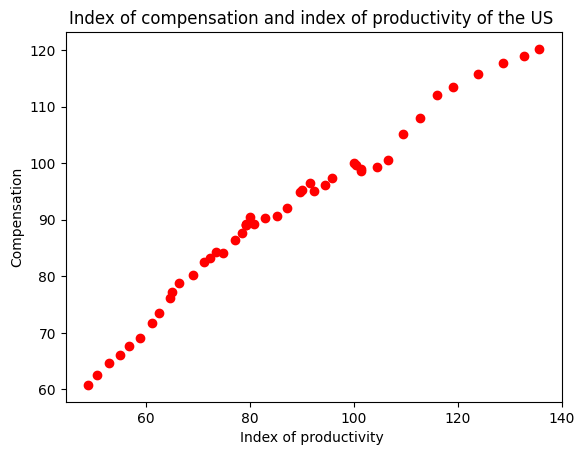

In [18]:
# scatter plot
plt.scatter(df.X,df.Y,color="red")
plt.title("Index of compensation and index of productivity of the US ")
plt.xlabel("Index of productivity ")
plt.ylabel("Compensation")
# plt.legend(loc="best")

In [5]:
# comment:Since the relationship between
# real compensation and labor productivity is expected to be positive, it is not surprising that
# the two variables are positively related

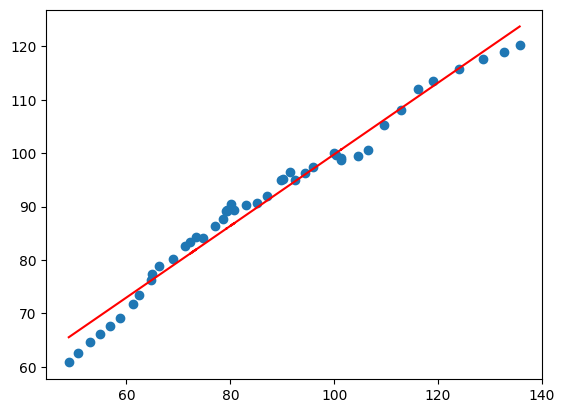

In [23]:
# fitting the linear regression to the data
x=df.X
y=df.Y
slope, intercept, r, p,std_err = stats.linregress(x, y)

def myfunc(x):
  return slope * x + intercept

mymodel = list(map(myfunc, x))

plt.scatter(x, y)
plt.plot(x, mymodel,color='red')
plt.show()

In [21]:
print("Slope",slope)
print("Intercept of the regression",intercept)
print("r_square",r)

Slope 0.670460367625615
Intercept of the regression 32.738653963322875
r_square 0.9882072102533059


## T-test

In [28]:
t_statistic, p_value = stats.ttest_ind(x, y)
 
# Set the significance level (alpha)
alpha = 0.05
# Compute the degrees of freedom (df) (n_x-1)+(n_y-1)

df = len(x)+len(y)-2

# Calculate the critical t-value
# ppf is used to find the critical t-value for a two-tailed test
critical_t = stats.t.ppf(1 - alpha/2, df)
 
 
# Print the results
print("T-value:", t_statistic)
print("P-Value:", p_value)
print("Critical t-value:", critical_t)
 
# Decision
print('With T-value')
if np.abs(t_statistic) >critical_t:
    print('There is significant difference between two groups')
else:
    print('No significant difference found between two groups')
 
print('With P-value')
if p_value >alpha:
    print('No evidence to reject the null hypothesis that a significant difference between the two groups')
else:
    print('Evidence found to reject the null hypothesis that a significant difference between the two groups')

T-value: -1.0817788582874186
P-Value: 0.28224083830632546
Critical t-value: 1.9866745405784678
With T-value
No significant difference found between two groups
With P-value
No evidence to reject the null hypothesis that a significant difference between the two groups


In [44]:
# from sklearn import linear_model
# from statsmodels.stats.stattools import durbin_watson
# reg_model=linear_model.LinearRegression()
# reg_model.fit(x,y)

# #perform Durbin-Watson test
# durbin_watson(reg_model.resid)